Analysed set up to the cutoff (31 Oct 2026): manual + deduplicated automated studies, written by `analysis_pubmed_new_post_revision.ipynb`

In [1]:
import pandas as pd
import os
import sys

# Add the parent directory to the Python path to import from data.export
sys.path.append(os.path.abspath(".."))

df_2025_class = df_2025 = pd.read_csv("export/classification_data_analysed.csv")

len(df_2025_class['study_id'].unique()) 

6773

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go


def plot_task_stacked_bar(
    df: pd.DataFrame,
    x_task: str,
    group_task: str,
    exclude_labels: dict | None = None,
    merge_labels: dict | None = None,
    value_name: str = "n_studies",
    figsize=(12, 12),
):
    """
    Create a stacked bar plot where each x-category (e.g. substance) is stacked by groups (e.g. conditions).

    Parameters:
    - df: DataFrame with columns `study_id`, `task`, `label` (or additional group column).
    - x_task: task name to use for x-axis categories (rows where `task==x_task` and `label` becomes x).
    - group_task: task name to use for stacking (rows where `task==group_task` and `label` becomes group),
                  or an existing column name in `df` to use directly as group.
    - exclude_labels: optional dict mapping task -> list of labels to exclude before plotting.
    - value_name: name for the aggregated count column.
    - figsize: figure size.

    Returns the counts DataFrame used for plotting.
    """
    data = df.copy()

    # Apply exclusions (task -> list[label])
    if exclude_labels:
        for task_name, labels in exclude_labels.items():
            data = data[~((data["task"] == task_name) & (data["label"].isin(labels)))]

    if merge_labels:
        for task_name, mapping in merge_labels.items():
            for new_label, old_labels in mapping.items():
                mask = (data["task"] == task_name) & (data["label"].isin(old_labels))
                data.loc[mask, "label"] = new_label

    total_nr_studies_per_x = {}
    task_filtered = data[data['task'] == x_task]

    for label in task_filtered['label'].unique():
        # filter according to label
        df_filtered = task_filtered[task_filtered['label'] == label]
        total_nr_studies_per_x[label] = len(df_filtered['study_id'].unique())
    

    # Build left (x) dataframe from x_task
    left = data[data["task"] == x_task][["study_id", "label"]].rename(columns={"label": "x"})

    # Build right (group) dataframe either from task rows or from an existing column
    if group_task in data["task"].unique():
        right = data[data["task"] == group_task][["study_id", "label"]].rename(columns={"label": "group"})
    elif group_task in data.columns:
        right = data[["study_id", group_task]].rename(columns={group_task: "group"})
    else:
        raise ValueError(f"group_task '{group_task}' not found as a task or column in the dataframe")

    # Merge on study_id and count occurrences
    merged = pd.merge(left, right, on="study_id")
    counts = (
        merged.groupby(["x", "group"])["study_id"]
        .nunique()
        .reset_index(name=value_name)
    )

    # Pivot for stacked plotting
    pivot = counts.pivot_table(index="x", columns="group", values=value_name, fill_value=0)

    # order by total frequency
    pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index]

    # Color palette
    groups = pivot.columns.tolist()
    colors = plt.get_cmap("tab20", len(groups))
    color_map = {g: colors(i) for i, g in enumerate(groups)}

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    result_rows = []

    for i, x_val in enumerate(pivot.index):
        row = pivot.loc[x_val]
        sorted_row = row.sort_values(ascending=False)

        bottom = 0
        total = total_nr_studies_per_x[x_val]

        for grp, val in sorted_row.items():
            if val == 0:
                continue

            pct = (val / total) * 100
            result_rows.append({
                "x": x_val,
                "group": grp,
                "count": int(val),
                "total": int(total),
                "percentage": pct,
            })

            ax.bar(
                x_val,
                val,
                bottom=bottom,
                color=color_map[grp],
                label=grp if i == 0 else "",
            )

            ax.text(
                x_val,
                bottom + val / 2,
                f"{int(val)}\n({pct:.1f}%)",
                ha="center",
                va="center",
                fontsize=7,
            )

            bottom += val

        ax.text(
            x_val,
            bottom + bottom * 0.02, 
            f"n={int(total)}",
            ha="center",
            va="bottom",
            fontsize=7,
            fontweight="bold",
        )

    # Legend cleanup
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), title=group_task, bbox_to_anchor=(1.05, 1), loc="upper left")

    # Formatting
    ax.set_title(f"{group_task} across {x_task}")
    ax.set_xlabel(x_task)
    ax.set_ylabel("Count")
    plt.xticks(rotation=90)

    plt.tight_layout()
    plt.show()

    return pd.DataFrame(result_rows)


def plot_task_stacked_bar_interactive(
    df: pd.DataFrame,
    x_task: str,
    group_task: str,
    exclude_labels: dict | None = None,
    merge_labels: dict | None = None,
    value_name: str = "n_studies",
):
    data = df.copy()

    if exclude_labels:
        for task_name, labels in exclude_labels.items():
            data = data[~((data["task"] == task_name) & (data["label"].isin(labels)))]

    if merge_labels:
        for task_name, mapping in merge_labels.items():
            for new_label, old_labels in mapping.items():
                mask = (data["task"] == task_name) & (data["label"].isin(old_labels))
                data.loc[mask, "label"] = new_label

    # Total studies per x
    task_filtered = data[data["task"] == x_task]
    total_nr_studies_per_x = (
        task_filtered.groupby("label")["study_id"]
        .nunique()
        .to_dict()
    )

    # Build left/right
    left = data[data["task"] == x_task][["study_id", "label"]].rename(columns={"label": "x"})

    if group_task in data["task"].unique():
        right = data[data["task"] == group_task][["study_id", "label"]].rename(columns={"label": "group"})
    elif group_task in data.columns:
        right = data[["study_id", group_task]].rename(columns={group_task: "group"})
    else:
        raise ValueError(f"group_task '{group_task}' not found")

    merged = pd.merge(left, right, on="study_id")

    counts = (
        merged.groupby(["x", "group"])["study_id"]
        .nunique()
        .reset_index(name=value_name)
    )

    # Pivot
    pivot = counts.pivot_table(index="x", columns="group", values=value_name, fill_value=0)

    # Sort x by total
    pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index]

    # Build result dataframe
    result_rows = []
    for x_val in pivot.index:
        total = total_nr_studies_per_x[x_val]
        for grp in pivot.columns:
            val = pivot.loc[x_val, grp]
            if val == 0:
                continue
            pct = (val / total) * 100
            result_rows.append({
                "x": x_val,
                "group": grp,
                "count": int(val),
                "total": int(total),
                "percentage": pct,
            })

    result_df = pd.DataFrame(result_rows)

    fig = go.Figure()

    unique_groups = list(pivot.columns)
    color_palette = px.colors.qualitative.Plotly
    color_map = {
        grp: color_palette[i % len(color_palette)]
        for i, grp in enumerate(unique_groups)
    }

    shown_groups = set()

    for x_val in pivot.index:
        row = pivot.loc[x_val]

        sorted_groups = row.sort_values(ascending=False)

        total = total_nr_studies_per_x[x_val]

        for grp, val in sorted_groups.items():
            if val == 0:
                continue

            pct = (val / total) * 100

            fig.add_trace(go.Bar(
                name=grp,
                x=[x_val],
                y=[val],
                marker=dict(color=color_map[grp]),
                customdata=[pct],
                hovertemplate=(
                    "<b>%{x}</b><br>"
                    f"{grp}<br>"
                    "Count: %{y}<br>"
                    "Percentage: %{customdata:.1f}%<extra></extra>"
                ),
                showlegend=grp not in shown_groups
            ))

            shown_groups.add(grp)

    fig.update_layout(
        barmode="stack",
        title=f"{group_task} across {x_task}",
        xaxis_title=x_task,
        yaxis_title="Count",
        xaxis_tickangle=-45,
        legend_title=group_task,
        height=700,
    )

    fig.show()

    return result_df


## Substances-Condition Analysis

### X: Substances, Y: Count of Studies, Segments: Conditions

In [3]:
counts = plot_task_stacked_bar_interactive(
    df_2025_class,
    x_task="Substances",
    group_task="Condition",
    exclude_labels={
        "Condition": ["Psychiatric condition", "Recreational Drug Use", "Healthy Participants"],
        "Substances": ["Combination Therapy", 'Ketamine']
    },
    merge_labels={
        "Substances": {
            "Ketamine": ["Ketamine", "R-Ketamine", "S-Ketamine"]
        }
    }
)

In [4]:
counts = plot_task_stacked_bar_interactive(
    df_2025_class,
    x_task="Substances",
    group_task="Condition",
    exclude_labels={
        "Condition": ["Psychiatric condition", "Recreational Drug Use", "Healthy Participants"],
        "Substances": ["Combination Therapy", 'Ketamine']
    },
    merge_labels={
        "Substances": {
            "Ketamine": ["Ketamine", "R-Ketamine", "S-Ketamine"]
        }
    }
)

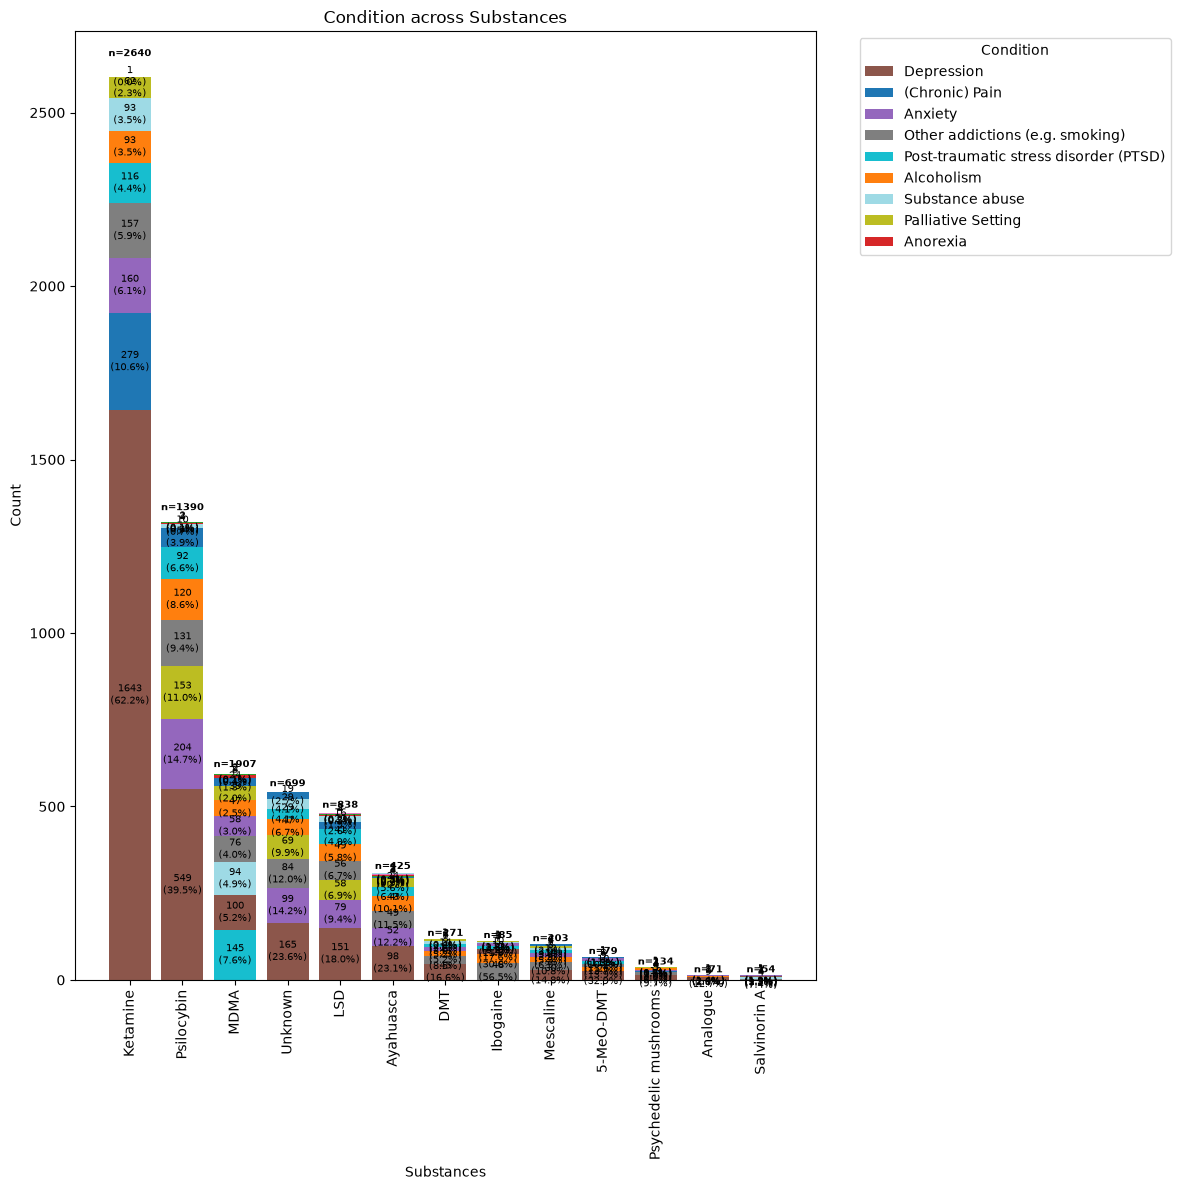

,x,group,count,total,percentage
0,Ketamine,Depression,1643,2640,62.234848
1,Ketamine,(Chronic) Pain,279,2640,10.568182
2,Ketamine,Anxiety,160,2640,6.060606
3,Ketamine,Other addictions (e.g. smoking),157,2640,5.946970
4,Ketamine,Post-traumatic stress disorder (PTSD),116,2640,4.393939
...,...,...,...,...,...
109,Salvinorin A,(Chronic) Pain,1,54,1.851852
110,Salvinorin A,Alcoholism,1,54,1.851852
111,Salvinorin A,Anxiety,1,54,1.851852
112,Salvinorin A,Palliative Setting,1,54,1.851852


In [5]:
plot_task_stacked_bar(
    df_2025_class,
    x_task="Substances",
    group_task="Condition",
    exclude_labels={
        "Condition": ["Psychiatric condition", "Recreational Drug Use", "Healthy Participants"],
        "Substances": ["Combination Therapy",  ]#"Ketamine", ]
    },
    merge_labels={
        "Substances": {
            "Ketamine": ["Ketamine", "R-Ketamine", "S-Ketamine"]
        }
    }
)

In [6]:
plot_task_stacked_bar_interactive(
    df_2025_class,
    x_task="Substances",
    group_task="Condition",
    exclude_labels={
        "Condition": ["Psychiatric condition", "Recreational Drug Use"],
        "Substances": ["Combination Therapy"]
    },
    merge_labels={
        "Substances": {
            "Ketamine": ["Ketamine", "R-Ketamine", "S-Ketamine"]
        }
    }
)

,x,group,count,total,percentage
0,Ketamine,(Chronic) Pain,279,2640,10.568182
1,Ketamine,Alcoholism,93,2640,3.522727
2,Ketamine,Anorexia,1,2640,0.037879
3,Ketamine,Anxiety,160,2640,6.060606
4,Ketamine,Depression,1643,2640,62.234848
...,...,...,...,...,...
122,Salvinorin A,Healthy Participants,53,54,98.148148
123,Salvinorin A,Other addictions (e.g. smoking),4,54,7.407407
124,Salvinorin A,Palliative Setting,1,54,1.851852
125,Salvinorin A,Post-traumatic stress disorder (PTSD),1,54,1.851852


### X: Condition, Y: Count of Studies, Segments: Substances

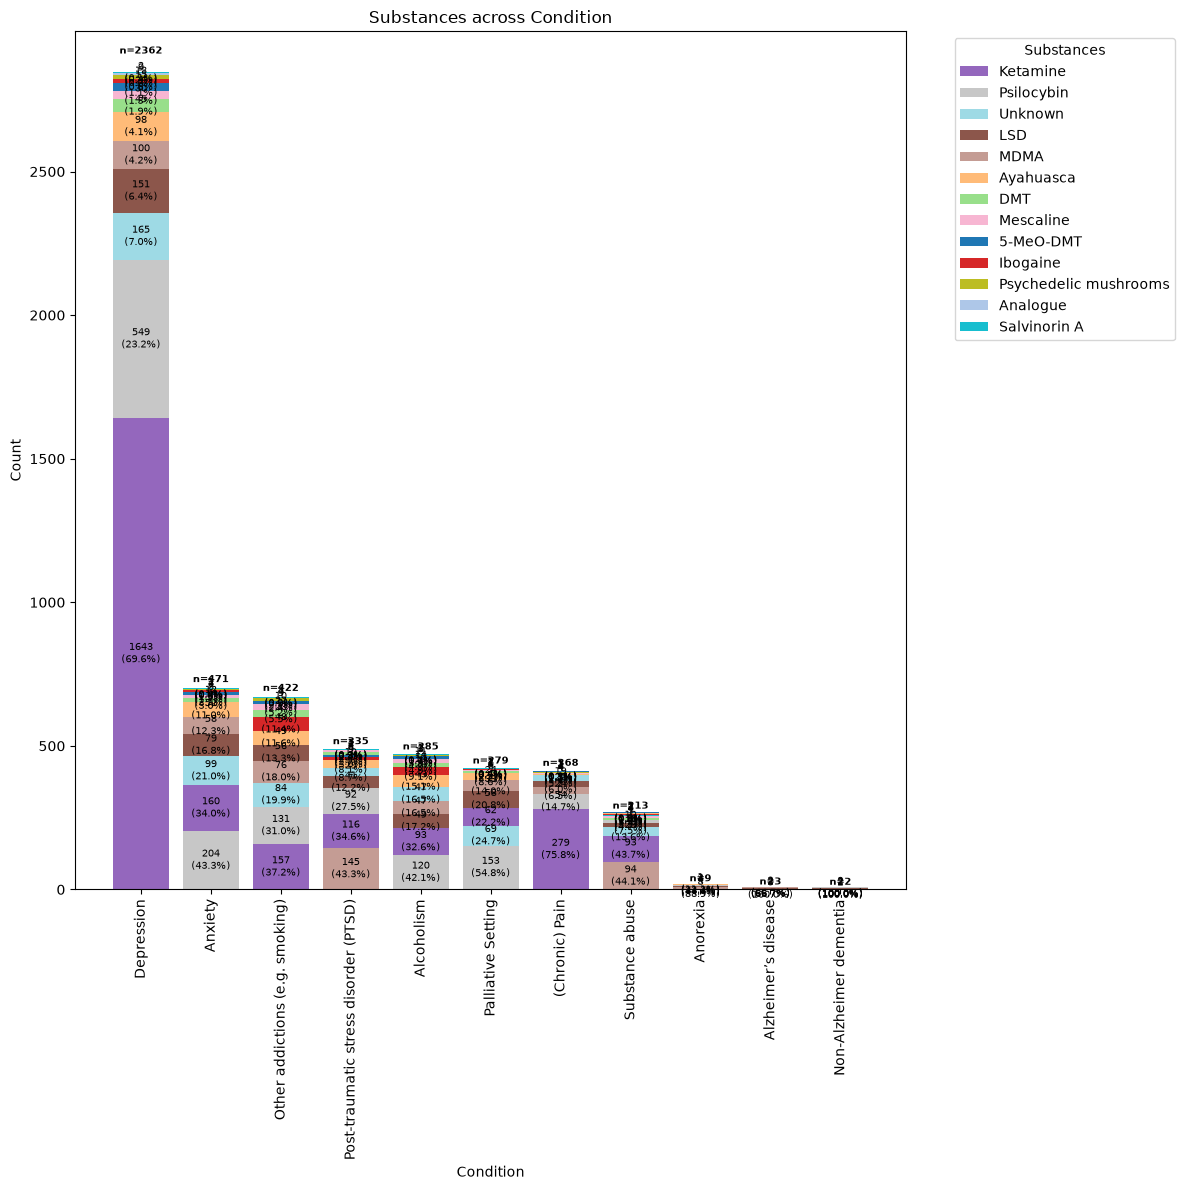

In [7]:
counts = plot_task_stacked_bar(
    df_2025_class,
    x_task="Condition",
    group_task="Substances",
    exclude_labels={
        "Condition": ["Psychiatric condition", "Recreational Drug Use", "Healthy Participants"],
        "Substances": ["Combination Therapy"]
    },
    merge_labels={
        "Substances": {
            "Ketamine": ["Ketamine", "R-Ketamine", "S-Ketamine"]
        }
    }
)

## Substances-Study Type/Control Analysis


### X: Substances, Y: Count of Studies, Segments: Study Type

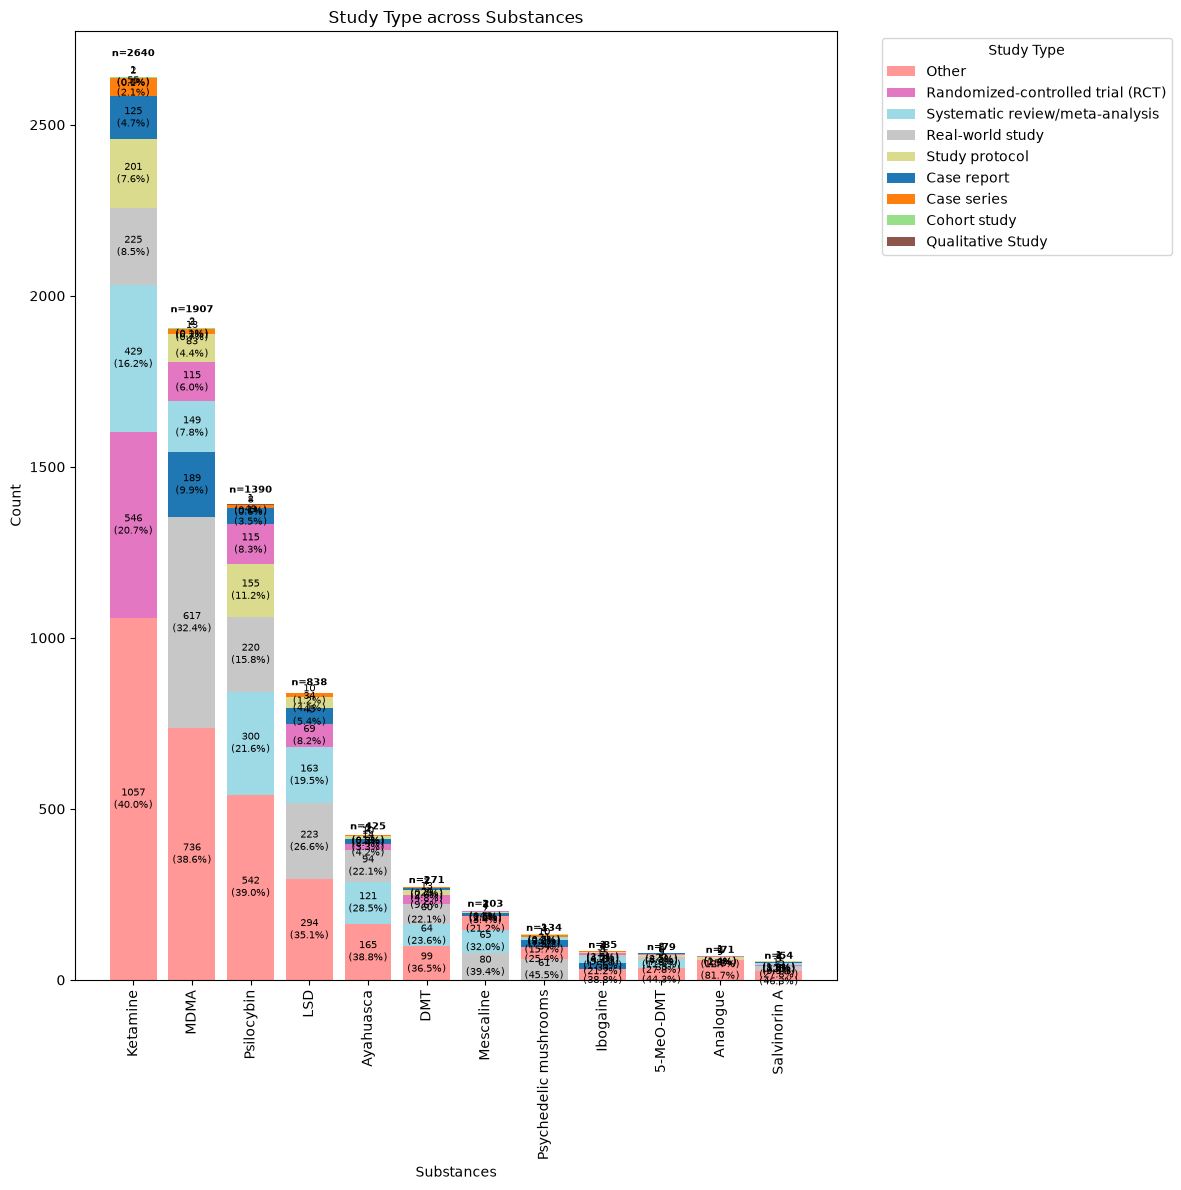

In [8]:
pct_sub_study_type = plot_task_stacked_bar(
    df_2025_class,
    x_task="Substances",
    group_task="Study Type",
    exclude_labels={   
        "Substances": ["Combination Therapy", "Unknown"],
        # "Study Type": ["Other"]
    },
        merge_labels={
        "Substances": {
            "Ketamine": ["Ketamine", "S-Ketamine", "R-Ketamine"]
        }
    }
)


In [9]:
plot_task_stacked_bar_interactive(
    df_2025_class,
    x_task="Substances",
    group_task="Study Type",
    exclude_labels={   
        "Substances": ["Combination Therapy", "Unknown"],
        # "Study Type": ["Other"]
    },
        merge_labels={
        "Substances": {
            "Ketamine": ["Ketamine", "S-Ketamine", "R-Ketamine"]
        }
    }
)

,x,group,count,total,percentage
0,Ketamine,Case report,125,2640,4.734848
1,Ketamine,Case series,55,2640,2.083333
2,Ketamine,Cohort study,2,2640,0.075758
3,Ketamine,Other,1057,2640,40.037879
4,Ketamine,Qualitative Study,1,2640,0.037879
...,...,...,...,...,...
82,Salvinorin A,Other,25,54,46.296296
83,Salvinorin A,Randomized-controlled trial (RCT),5,54,9.259259
84,Salvinorin A,Real-world study,15,54,27.777778
85,Salvinorin A,Study protocol,1,54,1.851852


What substance has the highest number/proportion of Randomized Controlled Trials (RCTs)?

In [10]:
rct_df = pct_sub_study_type[pct_sub_study_type["group"] == "Randomized-controlled trial (RCT)"]

rct_sorted = rct_df.sort_values(by="percentage", ascending=False)
print(rct_sorted)

                        x                              group  count  total  \
1                Ketamine  Randomized-controlled trial (RCT)    546   2640   
44                    DMT  Randomized-controlled trial (RCT)     26    271   
82           Salvinorin A  Randomized-controlled trial (RCT)      5     54   
22             Psilocybin  Randomized-controlled trial (RCT)    115   1390   
29                    LSD  Randomized-controlled trial (RCT)     69    838   
73              5-MeO-DMT  Randomized-controlled trial (RCT)      5     79   
13                   MDMA  Randomized-controlled trial (RCT)    115   1907   
66               Ibogaine  Randomized-controlled trial (RCT)      4     85   
36              Ayahuasca  Randomized-controlled trial (RCT)     18    425   
77               Analogue  Randomized-controlled trial (RCT)      2     71   
53              Mescaline  Randomized-controlled trial (RCT)      3    203   
61  Psychedelic mushrooms  Randomized-controlled trial (RCT)    

In [11]:
rct_sorted = rct_df.sort_values(by="count", ascending=False)
print(rct_sorted)


                        x                              group  count  total  \
1                Ketamine  Randomized-controlled trial (RCT)    546   2640   
13                   MDMA  Randomized-controlled trial (RCT)    115   1907   
22             Psilocybin  Randomized-controlled trial (RCT)    115   1390   
29                    LSD  Randomized-controlled trial (RCT)     69    838   
44                    DMT  Randomized-controlled trial (RCT)     26    271   
36              Ayahuasca  Randomized-controlled trial (RCT)     18    425   
73              5-MeO-DMT  Randomized-controlled trial (RCT)      5     79   
82           Salvinorin A  Randomized-controlled trial (RCT)      5     54   
66               Ibogaine  Randomized-controlled trial (RCT)      4     85   
53              Mescaline  Randomized-controlled trial (RCT)      3    203   
77               Analogue  Randomized-controlled trial (RCT)      2     71   
61  Psychedelic mushrooms  Randomized-controlled trial (RCT)    

Which substances have the highest number/proportion of Real-World Studies?

In [12]:
rct_df = pct_sub_study_type[pct_sub_study_type["group"] == "Real-world study"]

rct_sorted = rct_df.sort_values(by="percentage", ascending=False)
print(rct_sorted)

                        x             group  count  total  percentage
55  Psychedelic mushrooms  Real-world study     61    134   45.522388
48              Mescaline  Real-world study     80    203   39.408867
10                   MDMA  Real-world study    617   1907   32.354483
81           Salvinorin A  Real-world study     15     54   27.777778
27                    LSD  Real-world study    223    838   26.610979
43                    DMT  Real-world study     60    271   22.140221
35              Ayahuasca  Real-world study     94    425   22.117647
20             Psilocybin  Real-world study    220   1390   15.827338
71              5-MeO-DMT  Real-world study      9     79   11.392405
65               Ibogaine  Real-world study      8     85    9.411765
3                Ketamine  Real-world study    225   2640    8.522727
79               Analogue  Real-world study      1     71    1.408451


In [13]:
rct_sorted = rct_df.sort_values(by="count", ascending=False)
print(rct_sorted)

                        x             group  count  total  percentage
10                   MDMA  Real-world study    617   1907   32.354483
3                Ketamine  Real-world study    225   2640    8.522727
27                    LSD  Real-world study    223    838   26.610979
20             Psilocybin  Real-world study    220   1390   15.827338
35              Ayahuasca  Real-world study     94    425   22.117647
48              Mescaline  Real-world study     80    203   39.408867
55  Psychedelic mushrooms  Real-world study     61    134   45.522388
43                    DMT  Real-world study     60    271   22.140221
81           Salvinorin A  Real-world study     15     54   27.777778
71              5-MeO-DMT  Real-world study      9     79   11.392405
65               Ibogaine  Real-world study      8     85    9.411765
79               Analogue  Real-world study      1     71    1.408451


Which substances have the highest number/proportion of case reports for each condition?

In [14]:
rct_df = pct_sub_study_type[pct_sub_study_type["group"] == "Case report"]

rct_sorted = rct_df.sort_values(by="percentage", ascending=False)
print(rct_sorted)

                        x        group  count  total  percentage
63               Ibogaine  Case report     18     85   21.176471
57  Psychedelic mushrooms  Case report     21    134   15.671642
11                   MDMA  Case report    189   1907    9.910855
84           Salvinorin A  Case report      3     54    5.555556
30                    LSD  Case report     45    838    5.369928
5                Ketamine  Case report    125   2640    4.734848
23             Psilocybin  Case report     49   1390    3.525180
51              Mescaline  Case report      7    203    3.448276
37              Ayahuasca  Case report     14    425    3.294118
46                    DMT  Case report      7    271    2.583026
74              5-MeO-DMT  Case report      2     79    2.531646
78               Analogue  Case report      1     71    1.408451


In [15]:
review_df = pct_sub_study_type[pct_sub_study_type["group"] == "Systematic review/meta-analysis"]

review_sorted = review_df.sort_values(by="percentage", ascending=False)
print(review_sorted)

                        x                            group  count  total  \
49              Mescaline  Systematic review/meta-analysis     65    203   
34              Ayahuasca  Systematic review/meta-analysis    121    425   
70              5-MeO-DMT  Systematic review/meta-analysis     22     79   
42                    DMT  Systematic review/meta-analysis     64    271   
19             Psilocybin  Systematic review/meta-analysis    300   1390   
28                    LSD  Systematic review/meta-analysis    163    838   
64               Ibogaine  Systematic review/meta-analysis     15     85   
2                Ketamine  Systematic review/meta-analysis    429   2640   
12                   MDMA  Systematic review/meta-analysis    149   1907   
58  Psychedelic mushrooms  Systematic review/meta-analysis     10    134   
83           Salvinorin A  Systematic review/meta-analysis      4     54   

    percentage  
49   32.019704  
34   28.470588  
70   27.848101  
42   23.616236  
19

### X: Study Type, Y: Count of Studies, Segments: Substances

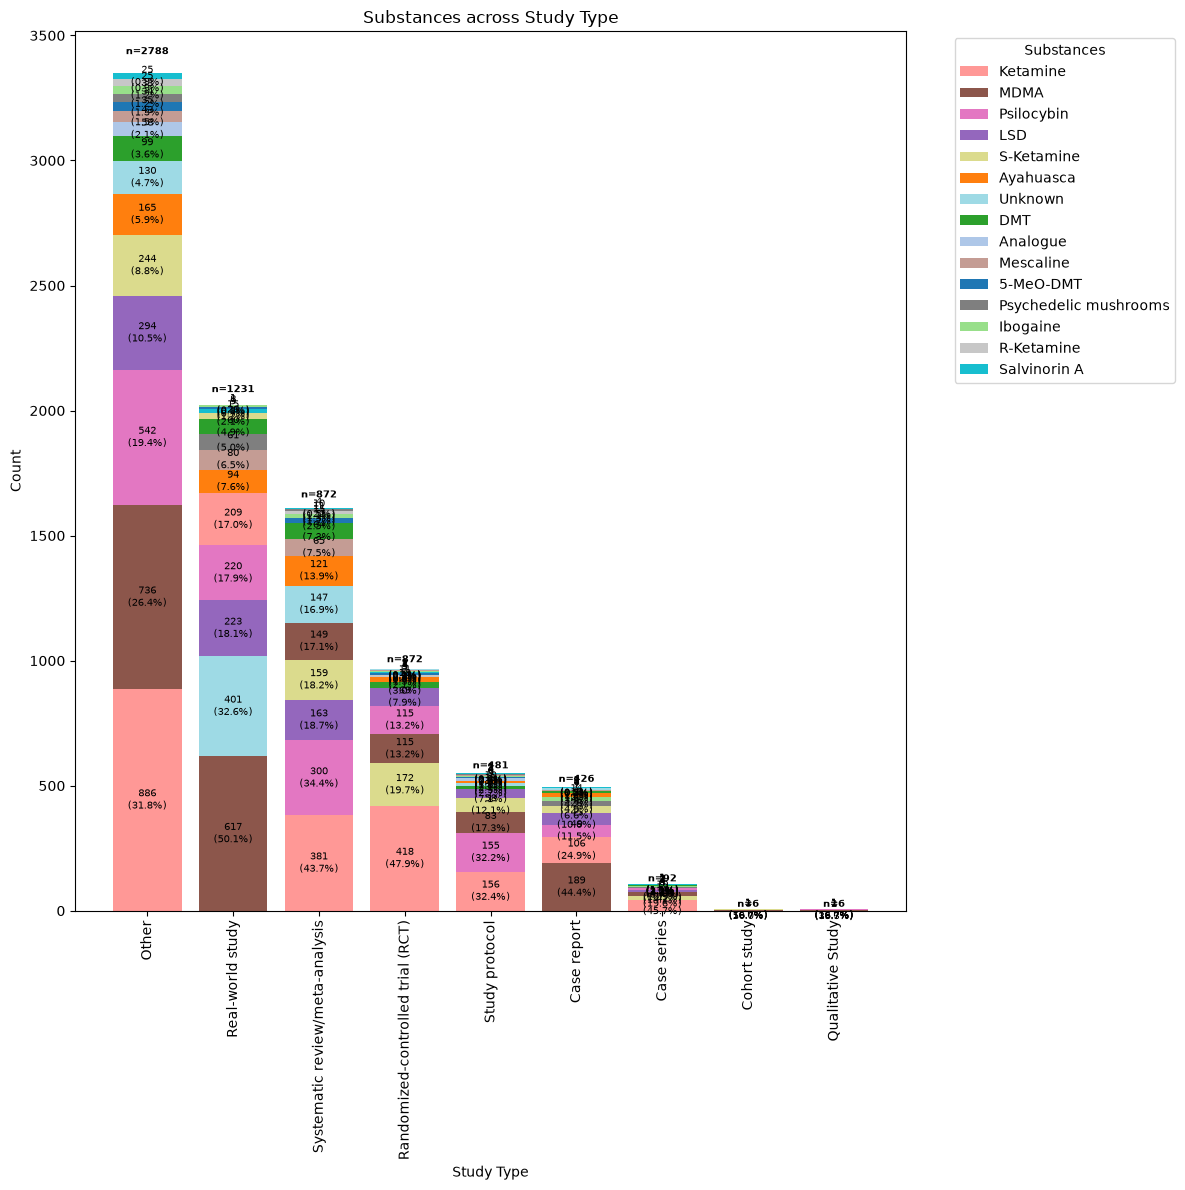

In [16]:
pct_study_type = plot_task_stacked_bar(
    df_2025_class,
    x_task="Study Type",
    group_task="Substances",
    exclude_labels={   
        "Substances": ["Combination Therapy"]
    }
)


### X: Substance, Y: Counts, Segments: Control

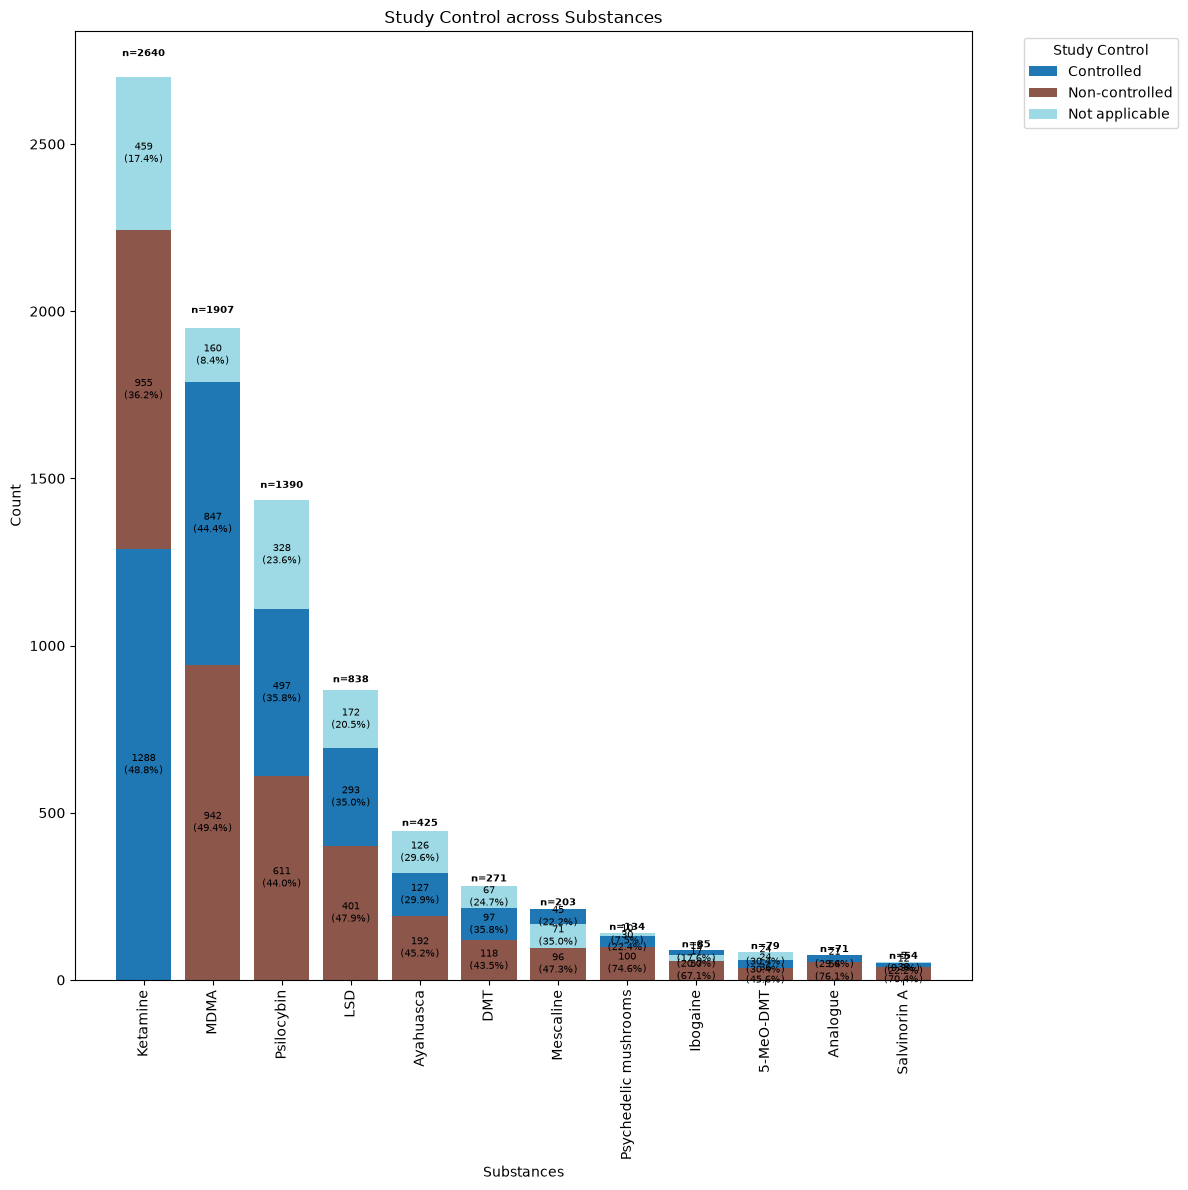

In [17]:
pct_control = plot_task_stacked_bar(
    df_2025_class,
    x_task="Substances",
    group_task="Study Control",
    exclude_labels={   
        "Substances": ["Combination Therapy", "Unknown"]
    },
    merge_labels={
        'Study Control': {
            'Controlled': ['Placebo', 'Other control', 'Active control']
        },
        'Substances': {
            'Ketamine': ['Ketamine', 'R-Ketamine', 'S-Ketamine']
        }
    }
)

In [18]:
control = pct_control[pct_control["group"] == "Controlled"]
rct_sorted = control.sort_values(by="percentage", ascending=False)
print(rct_sorted)

                        x       group  count  total  percentage
0                Ketamine  Controlled   1288   2640   48.787879
4                    MDMA  Controlled    847   1907   44.415312
16                    DMT  Controlled     97    271   35.793358
7              Psilocybin  Controlled    497   1390   35.755396
10                    LSD  Controlled    293    838   34.964200
28              5-MeO-DMT  Controlled     24     79   30.379747
13              Ayahuasca  Controlled    127    425   29.882353
31               Analogue  Controlled     21     71   29.577465
22  Psychedelic mushrooms  Controlled     30    134   22.388060
33           Salvinorin A  Controlled     12     54   22.222222
20              Mescaline  Controlled     45    203   22.167488
26               Ibogaine  Controlled     15     85   17.647059


In [19]:
uncontrol = pct_control[pct_control["group"] == "Non-controlled"]
controlled = uncontrol.sort_values(by="percentage", ascending=False)
print(controlled)

                        x           group  count  total  percentage
30               Analogue  Non-controlled     54     71   76.056338
21  Psychedelic mushrooms  Non-controlled    100    134   74.626866
32           Salvinorin A  Non-controlled     38     54   70.370370
24               Ibogaine  Non-controlled     57     85   67.058824
3                    MDMA  Non-controlled    942   1907   49.396959
9                     LSD  Non-controlled    401    838   47.852029
18              Mescaline  Non-controlled     96    203   47.290640
27              5-MeO-DMT  Non-controlled     36     79   45.569620
12              Ayahuasca  Non-controlled    192    425   45.176471
6              Psilocybin  Non-controlled    611   1390   43.956835
15                    DMT  Non-controlled    118    271   43.542435
1                Ketamine  Non-controlled    955   2640   36.174242


### X: Contorl, Y: Counts, Segements: Substances 

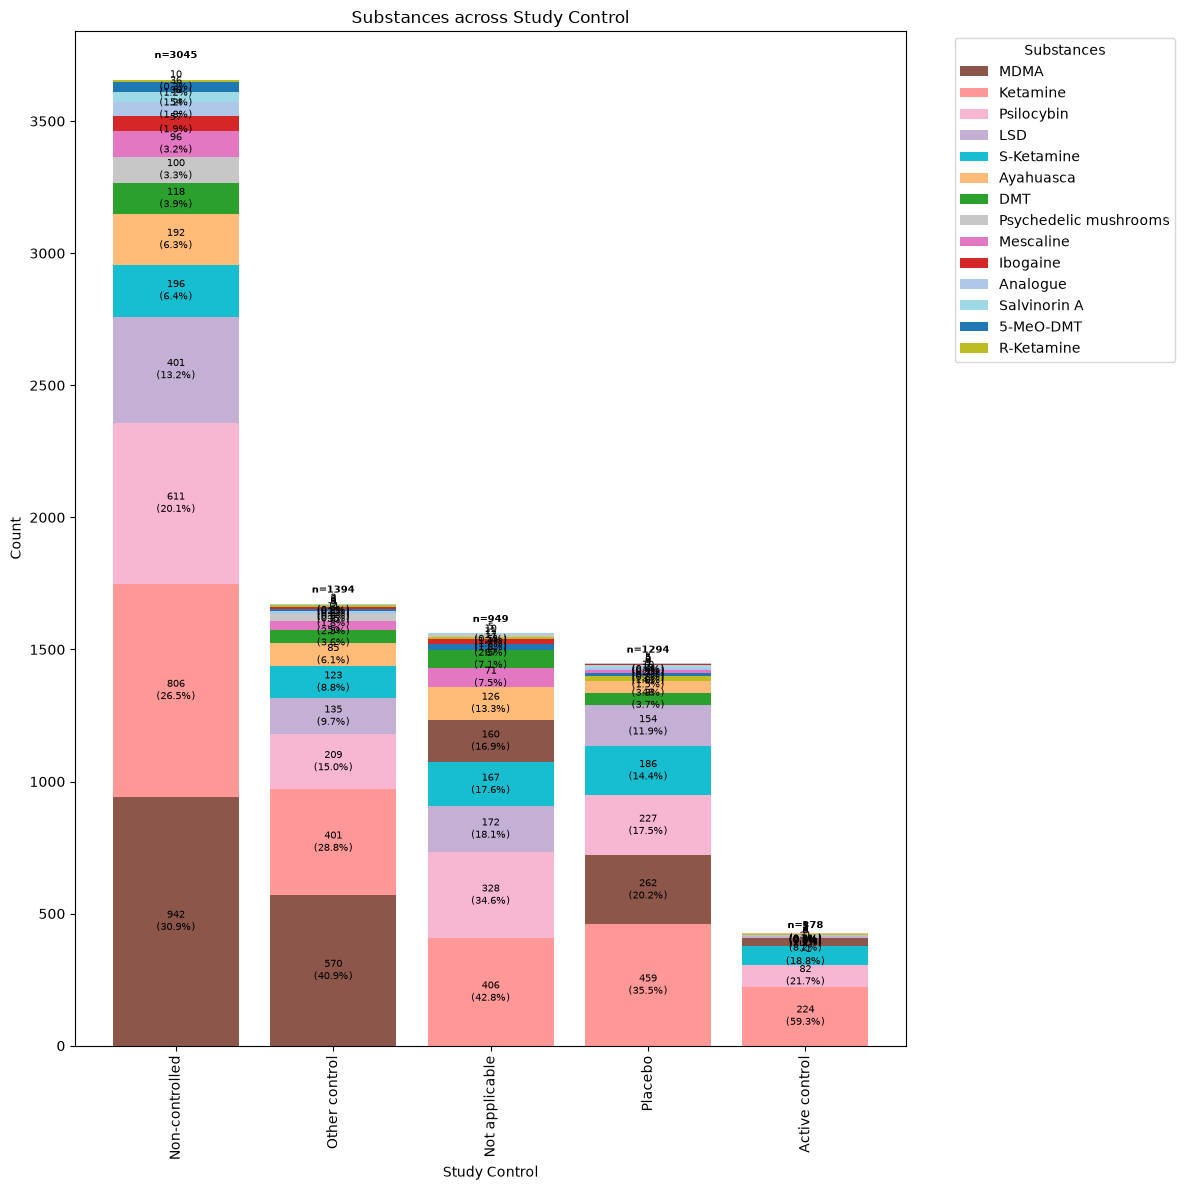

In [20]:
counts = plot_task_stacked_bar(
    df_2025_class,
    x_task="Study Control",
    group_task="Substances",
    exclude_labels={   
        "Substances": ["Combination Therapy", "Unknown"]
    }
)

## Substances-Study Purpose Analysis

### X: substances, Y: counts, Segments: study purpose

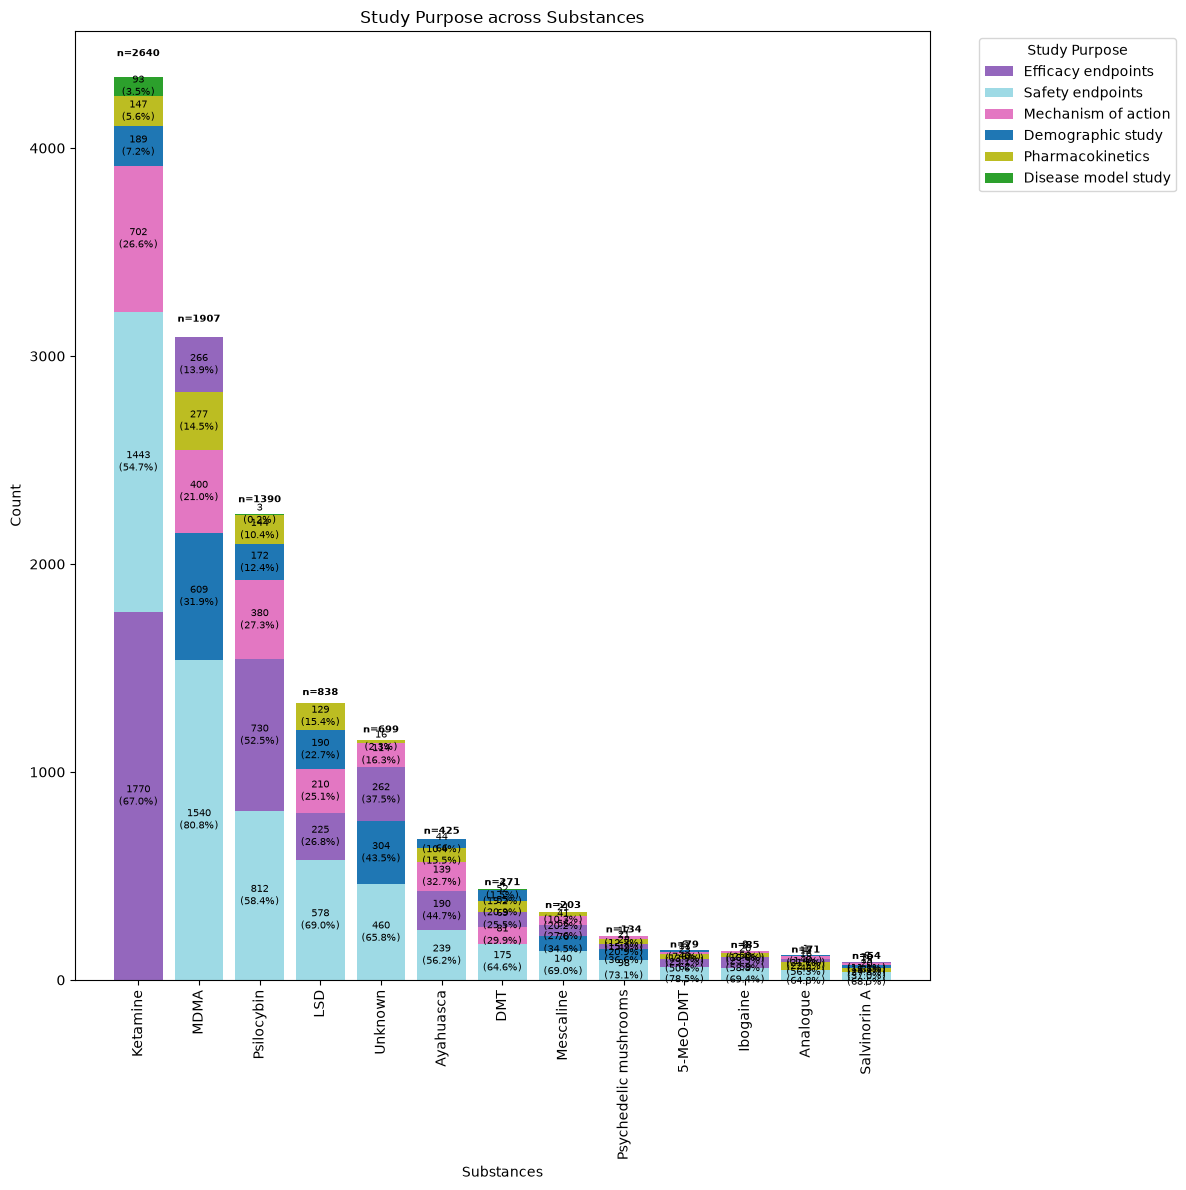

In [21]:
study_purpose = plot_task_stacked_bar(
    df_2025_class,
    x_task="Substances",
    group_task="Study Purpose",
    exclude_labels={
        "Substances": ['Other', 'Unkown', 'Combination Therapy']
    },
    merge_labels={
        "Substances": {
            "Ketamine": ["Ketamine", "S-Ketamine", "R-Ketamine"]
        }
    }
)


In [22]:
df_study_purpose = plot_task_stacked_bar_interactive(
    df_2025_class,
    x_task="Substances",
    group_task="Study Purpose",
    exclude_labels={
        "Substances": ['Other', 'Unkown', 'Combination Therapy']
    },
    merge_labels={
        "Substances": {
            "Ketamine": ["Ketamine", "S-Ketamine", "R-Ketamine"]
        }
    }
)


In [23]:
sp_df = study_purpose[study_purpose["group"] == "Mechanism of action"]

sp_sorted = sp_df.sort_values(by="percentage", ascending=False)
print(sp_sorted)

                        x                group  count  total  percentage
29              Ayahuasca  Mechanism of action    139    425   32.705882
33                    DMT  Mechanism of action     81    271   29.889299
13             Psilocybin  Mechanism of action    380   1390   27.338129
2                Ketamine  Mechanism of action    702   2640   26.590909
19                    LSD  Mechanism of action    210    838   25.059666
61               Analogue  Mechanism of action     15     71   21.126761
8                    MDMA  Mechanism of action    400   1907   20.975354
41              Mescaline  Mechanism of action     41    203   20.197044
66           Salvinorin A  Mechanism of action     10     54   18.518519
25                Unknown  Mechanism of action    114    699   16.309013
51              5-MeO-DMT  Mechanism of action     11     79   13.924051
47  Psychedelic mushrooms  Mechanism of action     17    134   12.686567
56               Ibogaine  Mechanism of action     

In [24]:
sp_df = study_purpose[study_purpose["group"] == "Demographic study"]

sp_sorted = sp_df.sort_values(by="percentage", ascending=False)
print(sp_sorted)

                        x              group  count  total  percentage
23                Unknown  Demographic study    304    699   43.490701
44  Psychedelic mushrooms  Demographic study     49    134   36.567164
39              Mescaline  Demographic study     70    203   34.482759
7                    MDMA  Demographic study    609   1907   31.934976
65           Salvinorin A  Demographic study     15     54   27.777778
20                    LSD  Demographic study    190    838   22.673031
36                    DMT  Demographic study     52    271   19.188192
14             Psilocybin  Demographic study    172   1390   12.374101
31              Ayahuasca  Demographic study     44    425   10.352941
52              5-MeO-DMT  Demographic study      6     79    7.594937
3                Ketamine  Demographic study    189   2640    7.159091
57               Ibogaine  Demographic study      2     85    2.352941
62               Analogue  Demographic study      1     71    1.408451


In [25]:
sp_sorted = sp_df.sort_values(by="count", ascending=False)
print(sp_sorted)


                        x              group  count  total  percentage
7                    MDMA  Demographic study    609   1907   31.934976
23                Unknown  Demographic study    304    699   43.490701
20                    LSD  Demographic study    190    838   22.673031
3                Ketamine  Demographic study    189   2640    7.159091
14             Psilocybin  Demographic study    172   1390   12.374101
39              Mescaline  Demographic study     70    203   34.482759
36                    DMT  Demographic study     52    271   19.188192
44  Psychedelic mushrooms  Demographic study     49    134   36.567164
31              Ayahuasca  Demographic study     44    425   10.352941
65           Salvinorin A  Demographic study     15     54   27.777778
52              5-MeO-DMT  Demographic study      6     79    7.594937
57               Ibogaine  Demographic study      2     85    2.352941
62               Analogue  Demographic study      1     71    1.408451


### X: Study Purpose, Y: Counts, Segments: Substances

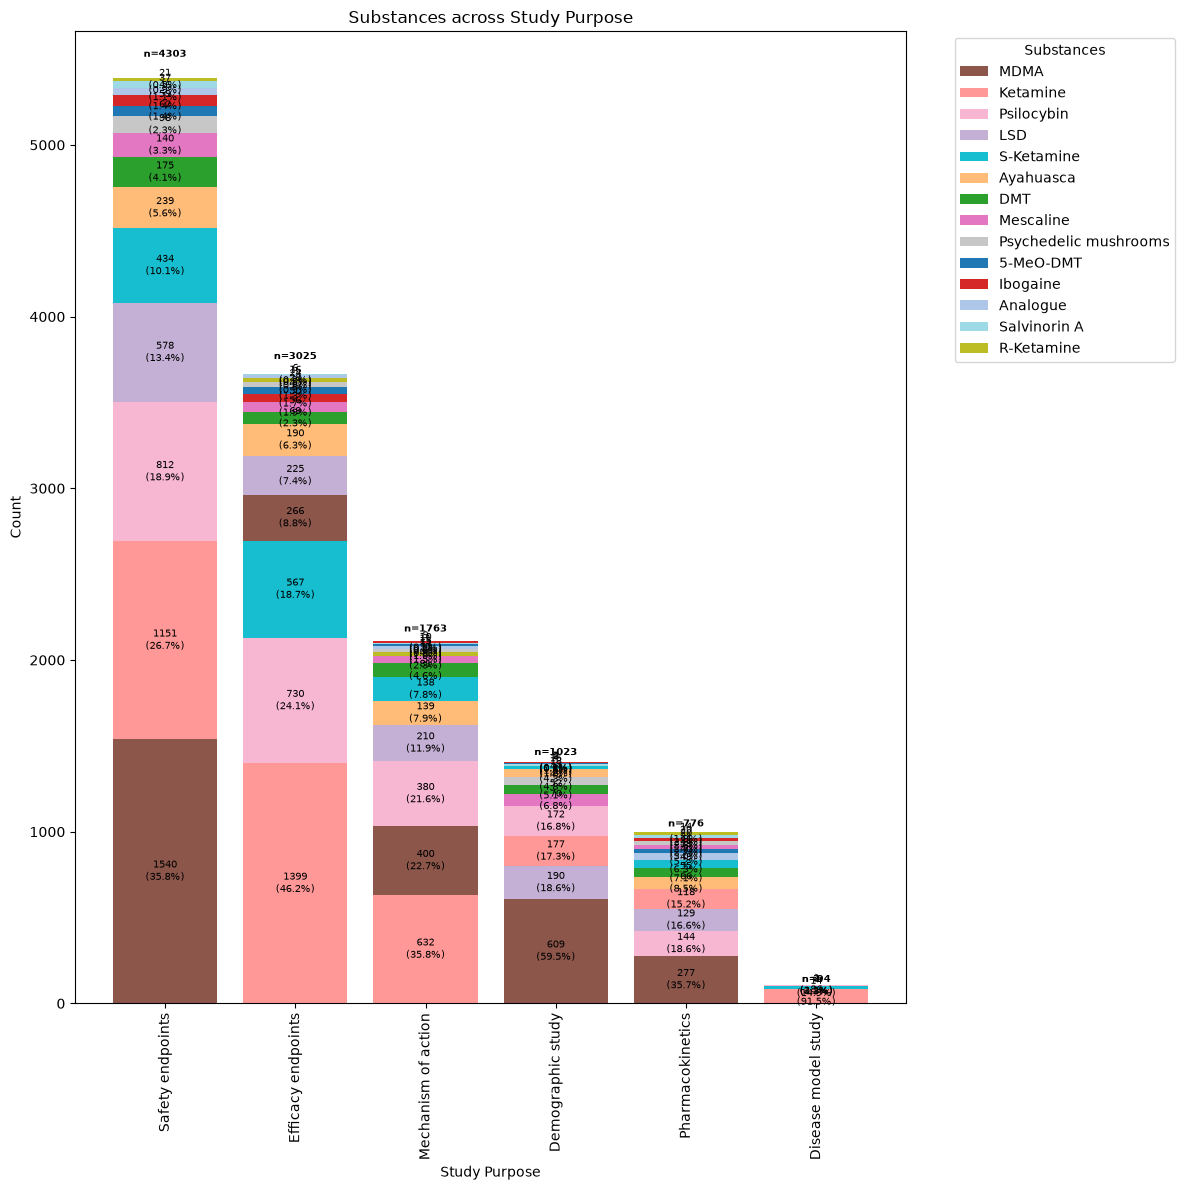

In [26]:
counts = plot_task_stacked_bar(
    df_2025_class,
    x_task="Study Purpose",
    group_task="Substances",
    exclude_labels={
        "Substances": ['Other', 'Unknown', 'Combination Therapy']
    }
)